# 02 — Exploratory Data Analysis

## Objective
Investigate visual, spectral, statistical, geometric, and spatial properties of the xView2 training dataset to guide preprocessing, loss weighting, and architecture selection.

## 1. Environment Setup, Reproducibility & Tile Sampling
Sets project paths, fixes random seeds (`RANDOM_STATE = 42`), configures plot defaults, and selects a deterministic 100-tile subset for spectral sampling.

In [1]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from shapely import wkt
from shapely.validation import explain_validity

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_ROOT = PROJECT_ROOT / "dataset"
TRAIN_IMAGES_DIR = DATASET_ROOT / "train" / "images"
TRAIN_LABELS_DIR = DATASET_ROOT / "train" / "labels"

assert TRAIN_IMAGES_DIR.exists() and TRAIN_LABELS_DIR.exists()

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.dpi"] = 100

pre_images = {p.stem.replace("_pre_disaster", ""): p for p in TRAIN_IMAGES_DIR.glob("*_pre_disaster.png")}
post_images = {p.stem.replace("_post_disaster", ""): p for p in TRAIN_IMAGES_DIR.glob("*_post_disaster.png")}
common_tiles = sorted(set(pre_images) & set(post_images))
sampled_tiles = random.sample(common_tiles, min(100, len(common_tiles)))
viz_tiles = random.sample(sampled_tiles, 4)

print(f"Training pairs: {len(common_tiles):,} | Sampled for spectral EDA: {len(sampled_tiles)}")

Training pairs: 2,799 | Sampled for spectral EDA: 100


## 2. Visual Pair Comparison & Pixel-Level Differences
Compares pre-disaster vs. post-disaster satellite RGB pairs alongside absolute difference maps and Mean Absolute Error (MAE) excluding black no-data borders.

                        tile_id    mae  valid_pct
0   hurricane-florence_00000380  18.05      100.0
1     midwest-flooding_00000317  52.20       83.4
2  santa-rosa-wildfire_00000149  17.46      100.0
3    hurricane-matthew_00000017  20.43      100.0


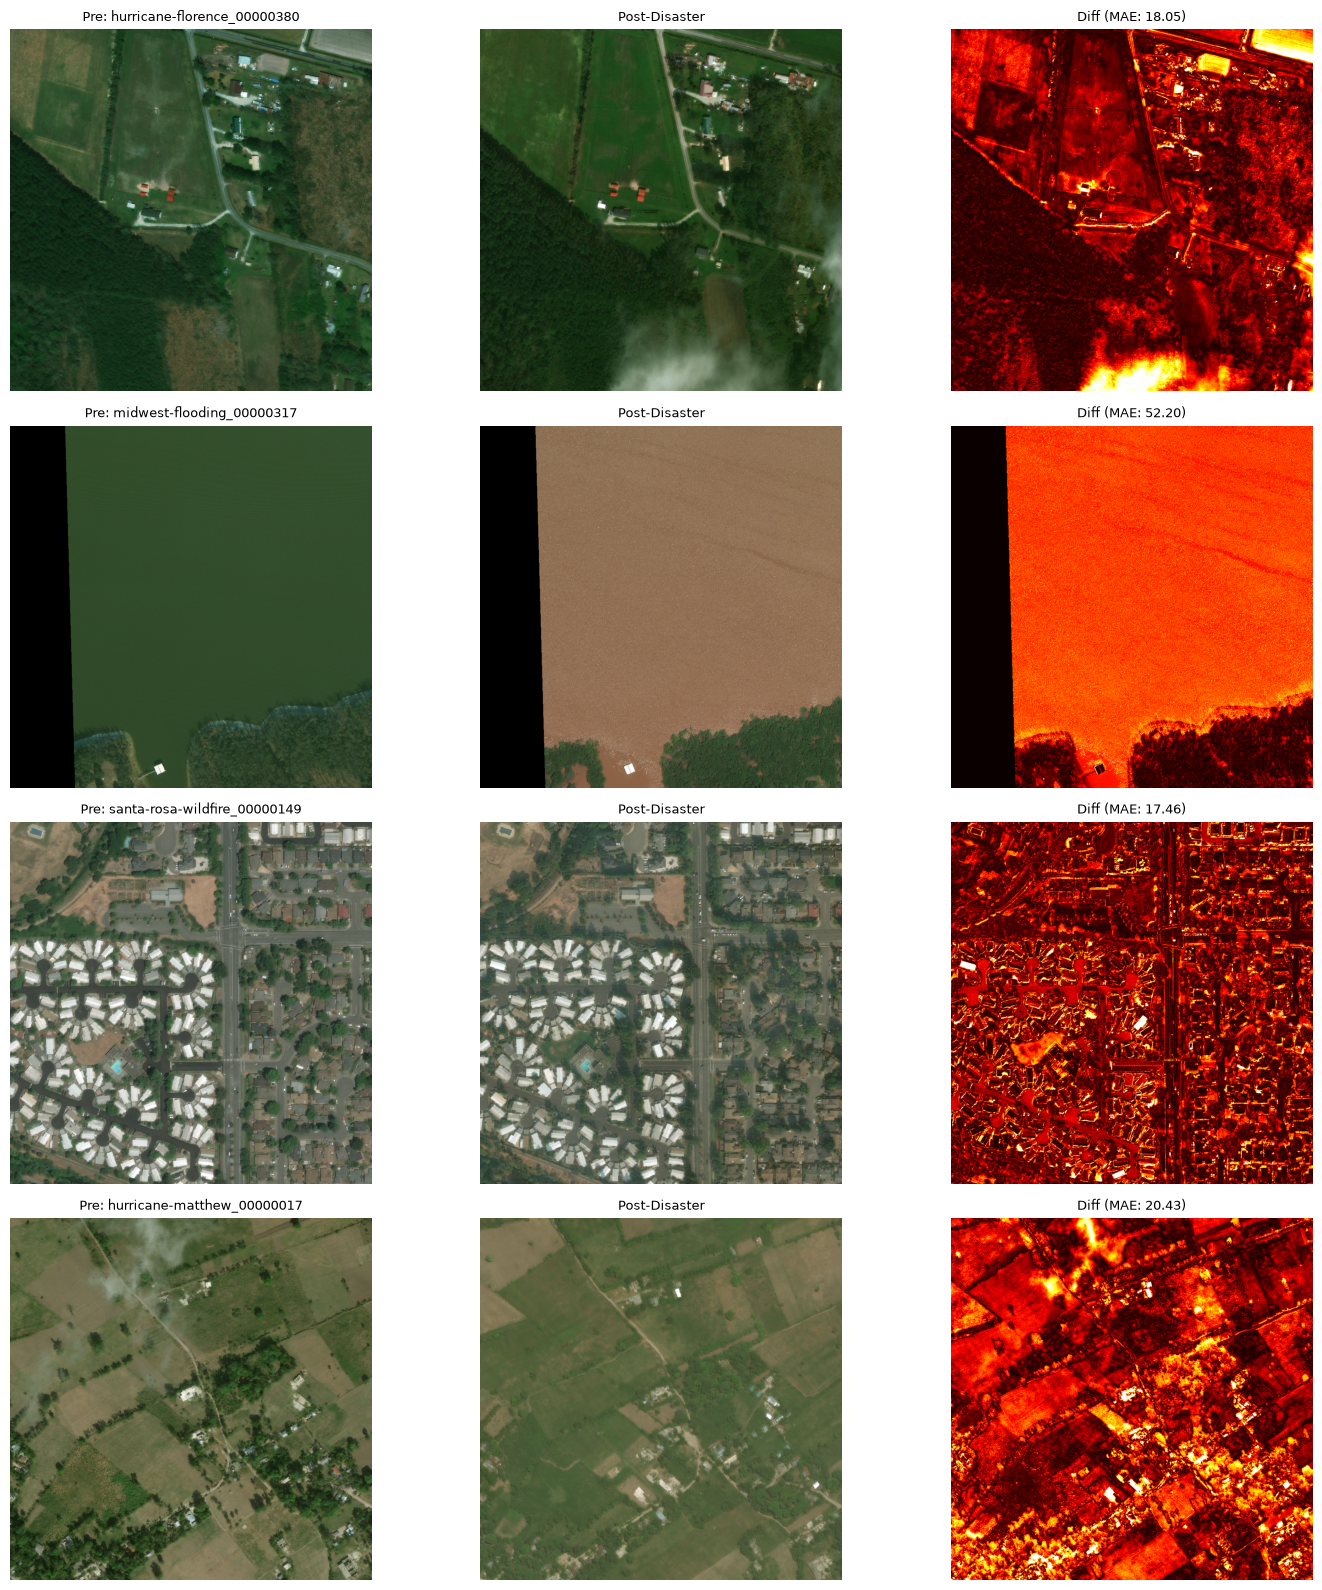

In [2]:
diff_records = []
fig, axes = plt.subplots(len(viz_tiles), 3, figsize=(15, 4 * len(viz_tiles)))

for idx, tile_id in enumerate(viz_tiles):
    pre = np.array(Image.open(pre_images[tile_id]).convert("RGB"), dtype=np.float32)
    post = np.array(Image.open(post_images[tile_id]).convert("RGB"), dtype=np.float32)
    diff = np.abs(post - pre)
    valid = np.any(pre > 0, axis=2) & np.any(post > 0, axis=2)
    mae = float(np.mean(diff[valid])) if np.any(valid) else 0.0
    diff_records.append({"tile_id": tile_id, "mae": round(mae, 2), "valid_pct": round(valid.mean() * 100, 1)})
    vmax = max(float(np.percentile(diff[valid], 99)), 1.0) if np.any(valid) else 1.0
    axes[idx, 0].imshow(pre.astype(np.uint8))
    axes[idx, 0].set_title(f"Pre: {tile_id}", fontsize=9)
    axes[idx, 1].imshow(post.astype(np.uint8))
    axes[idx, 1].set_title("Post-Disaster", fontsize=9)
    axes[idx, 2].imshow(diff.mean(axis=2), cmap="hot", vmin=0, vmax=vmax)
    axes[idx, 2].set_title(f"Diff (MAE: {mae:.2f})", fontsize=9)
    for ax in axes[idx]:
        ax.axis("off")

plt.tight_layout()
plt.show()
display(pd.DataFrame(diff_records))

## 3. RGB Intensity Distribution Analysis
Samples 5,000 non-black pixels per sampled tile to compare channel intensity distributions between pre- and post-disaster imagery.

  Channel  Pre Mean  Pre Std  Post Mean  Post Std
0     Red     81.14    37.47      80.24     38.92
1   Green     90.94    30.91      88.95     31.69
2    Blue     67.36    31.18      65.74     31.53


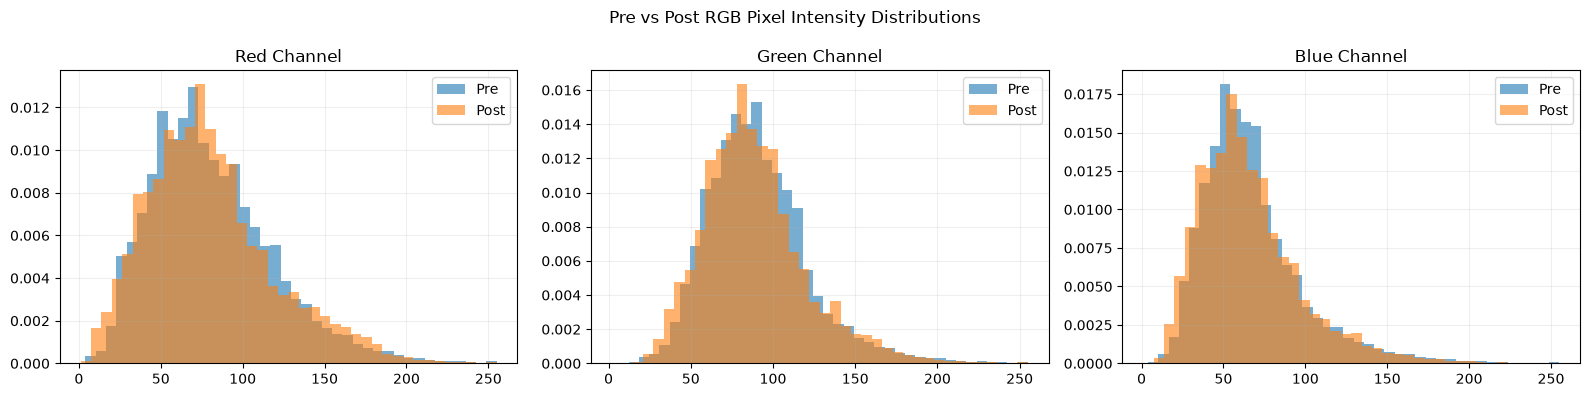

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
pre_samples, post_samples = [], []

for tile_id in sampled_tiles:
    for target_list, path in [(pre_samples, pre_images[tile_id]), (post_samples, post_images[tile_id])]:
        img = np.array(Image.open(path).convert("RGB"))
        valid = img[np.any(img > 0, axis=2)]
        if len(valid) > 0:
            idx = rng.choice(len(valid), size=min(5000, len(valid)), replace=False)
            target_list.append(valid[idx])

pre_px = np.concatenate(pre_samples)
post_px = np.concatenate(post_samples)
channels = ["Red", "Green", "Blue"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
summary = []
for i, ch in enumerate(channels):
    axes[i].hist(pre_px[:, i], bins=40, alpha=0.6, density=True, label="Pre")
    axes[i].hist(post_px[:, i], bins=40, alpha=0.6, density=True, label="Post")
    axes[i].set_title(f"{ch} Channel")
    axes[i].legend()
    axes[i].grid(alpha=0.2)
    summary.append({"Channel": ch, "Pre Mean": pre_px[:, i].mean(), "Pre Std": pre_px[:, i].std(), "Post Mean": post_px[:, i].mean(), "Post Std": post_px[:, i].std()})

plt.suptitle("Pre vs Post RGB Pixel Intensity Distributions")
plt.tight_layout()
plt.show()
display(pd.DataFrame(summary).round(2))

## 4. Building Counts, Class Imbalance & Per-Disaster Breakdown
Parses all training JSON labels in one pass to examine empty tiles, overall damage class imbalance, and severity skew across disaster events.

Total Buildings: 162,787 | Tiles with Buildings: 2,283/2,799 (81.6%)


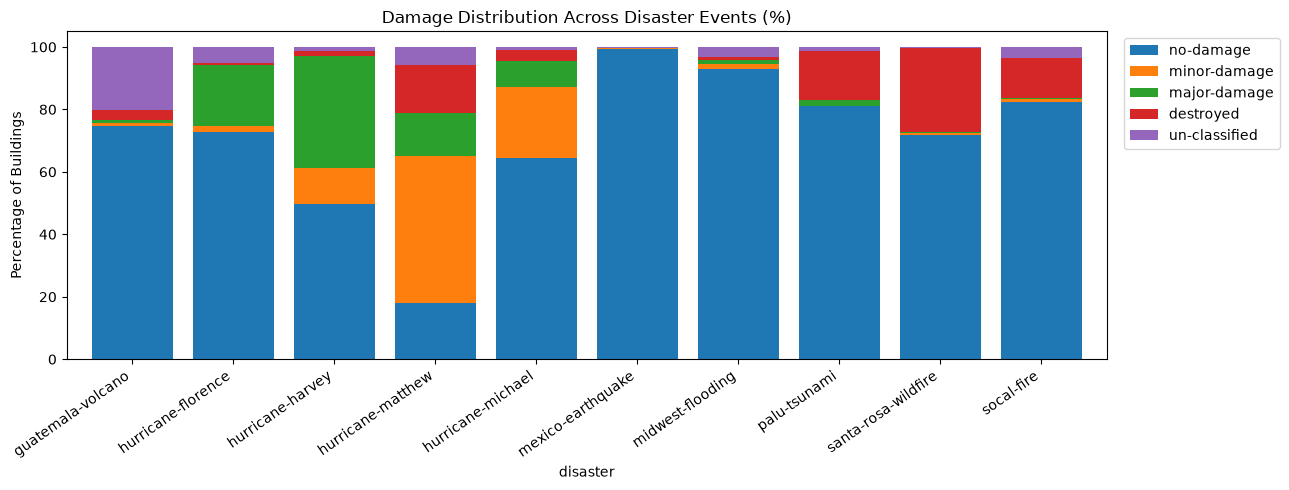

In [4]:
records = []
for label_path in sorted(TRAIN_LABELS_DIR.glob("*_post_disaster.json")):
    tile_id = label_path.stem.replace("_post_disaster", "")
    with open(label_path, "r") as f:
        data = json.load(f)
    disaster = data.get("metadata", {}).get("disaster", tile_id.rsplit("_", 1)[0])
    for feat in data.get("features", {}).get("xy", []):
        props = feat.get("properties", {})
        if props.get("feature_type") == "building":
            records.append({
                "tile_id": tile_id,
                "disaster": disaster,
                "uid": props.get("uid"),
                "subtype": props.get("subtype"),
                "wkt": feat.get("wkt")
            })

post_df = pd.DataFrame(records)
tiles_with_bldgs = post_df["tile_id"].nunique()
print(f"Total Buildings: {len(post_df):,} | Tiles with Buildings: {tiles_with_bldgs:,}/{len(common_tiles):,} ({tiles_with_bldgs/len(common_tiles)*100:.1f}%)")

dmg_ct = pd.crosstab(post_df["disaster"], post_df["subtype"])
dmg_pct = dmg_ct.div(dmg_ct.sum(axis=1), axis=0) * 100
cols = [c for c in ["no-damage", "minor-damage", "major-damage", "destroyed", "un-classified"] if c in dmg_pct.columns]
dmg_pct[cols].plot(kind="bar", stacked=True, figsize=(13, 5), width=0.8)
plt.title("Damage Distribution Across Disaster Events (%)")
plt.ylabel("Percentage of Buildings")
plt.xticks(rotation=35, ha="right")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 5. Building Polygon Geometry & Anomaly Audit
Parses all 162,787 building polygons once to measure footprint areas, damage-stratified size distributions, invalid geometries, and visually inspect extreme polygon anomalies.

Parsed Geometries: 162,787 | Invalid Geometries: 1 | Median Area: 654.0 px^2


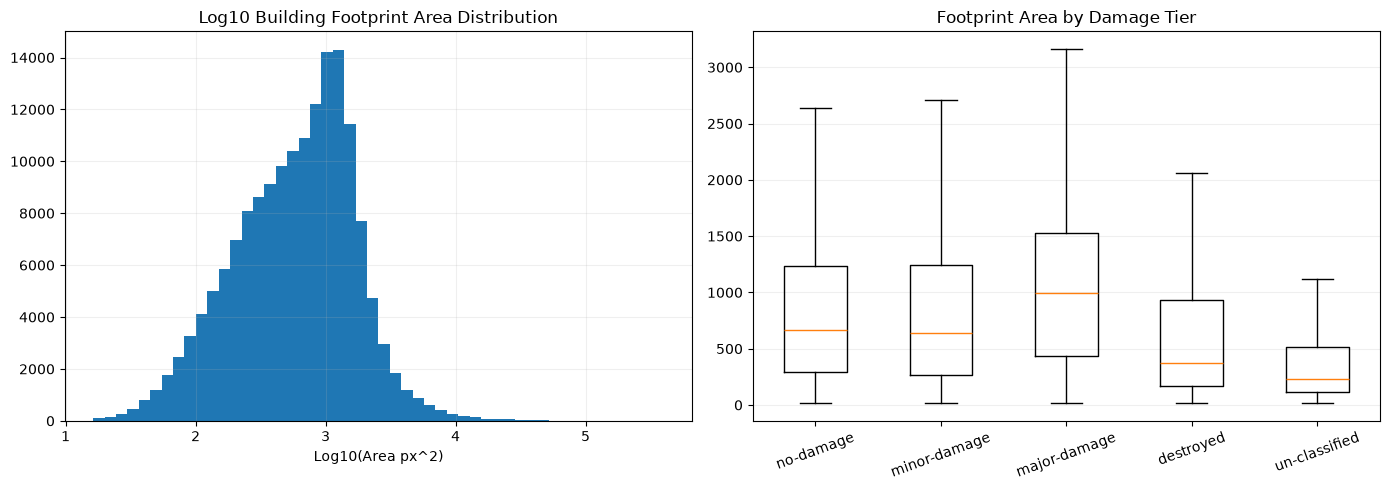

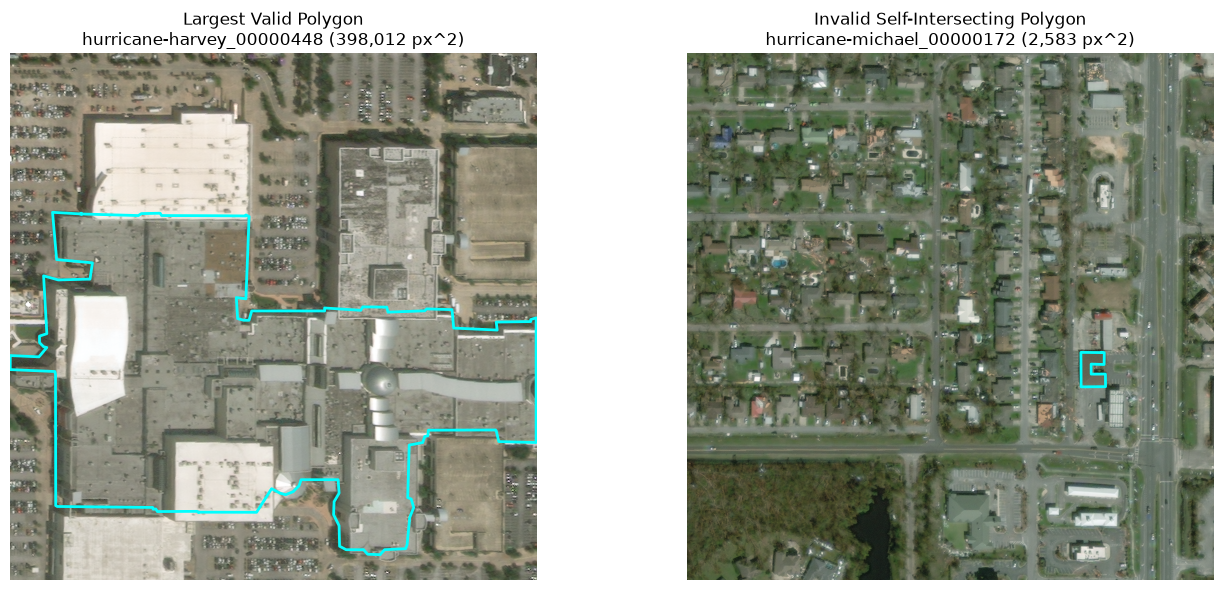

In [5]:
geom_records = []
for _, row in post_df.iterrows():
    try:
        geom = wkt.loads(row["wkt"])
        if geom.is_empty:
            continue
        min_x, min_y, max_x, max_y = geom.bounds
        geom_records.append({
            "tile_id": row["tile_id"],
            "uid": row["uid"],
            "subtype": row["subtype"],
            "area": geom.area,
            "perimeter": geom.length,
            "is_valid": geom.is_valid,
            "outside_bounds": (min_x < 0 or min_y < 0 or max_x > 1024 or max_y > 1024),
            "geom": geom
        })
    except Exception:
        continue

geom_df = pd.DataFrame(geom_records)
print(f"Parsed Geometries: {len(geom_df):,} | Invalid Geometries: {(~geom_df['is_valid']).sum()} | Median Area: {geom_df['area'].median():.1f} px^2")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pos_area = geom_df.loc[geom_df["area"] > 0, "area"]
axes[0].hist(np.log10(pos_area), bins=50)
axes[0].set_title("Log10 Building Footprint Area Distribution")
axes[0].set_xlabel("Log10(Area px^2)")
axes[0].grid(alpha=0.2)

order = ["no-damage", "minor-damage", "major-damage", "destroyed", "un-classified"]
axes[1].boxplot([geom_df.loc[geom_df["subtype"] == d, "area"].values for d in order], tick_labels=order, showfliers=False)
axes[1].set_title("Footprint Area by Damage Tier")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

largest = geom_df.loc[geom_df["area"].idxmax()]
invalid_rows = geom_df[~geom_df["is_valid"]]
cases = [("Largest Valid Polygon", largest)] + ([("Invalid Self-Intersecting Polygon", invalid_rows.iloc[0])] if len(invalid_rows) > 0 else [])
fig, axes = plt.subplots(1, len(cases), figsize=(7 * len(cases), 6))
if len(cases) == 1:
    axes = [axes]
for ax, (title, row) in zip(axes, cases):
    img = np.array(Image.open(post_images[row["tile_id"]]).convert("RGB"))
    ax.imshow(img)
    if row["geom"].geom_type == "Polygon":
        x, y = row["geom"].exterior.xy
        ax.plot(x, y, linewidth=2, color="cyan")
    ax.set_title(f"{title}\n{row['tile_id']} ({row['area']:,.0f} px^2)")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Spatial Damage Concentration & 4×4 Regional Heatmaps
Maps centroid locations and local damage density across 4×4 image quadrants for four representative disaster tiles.

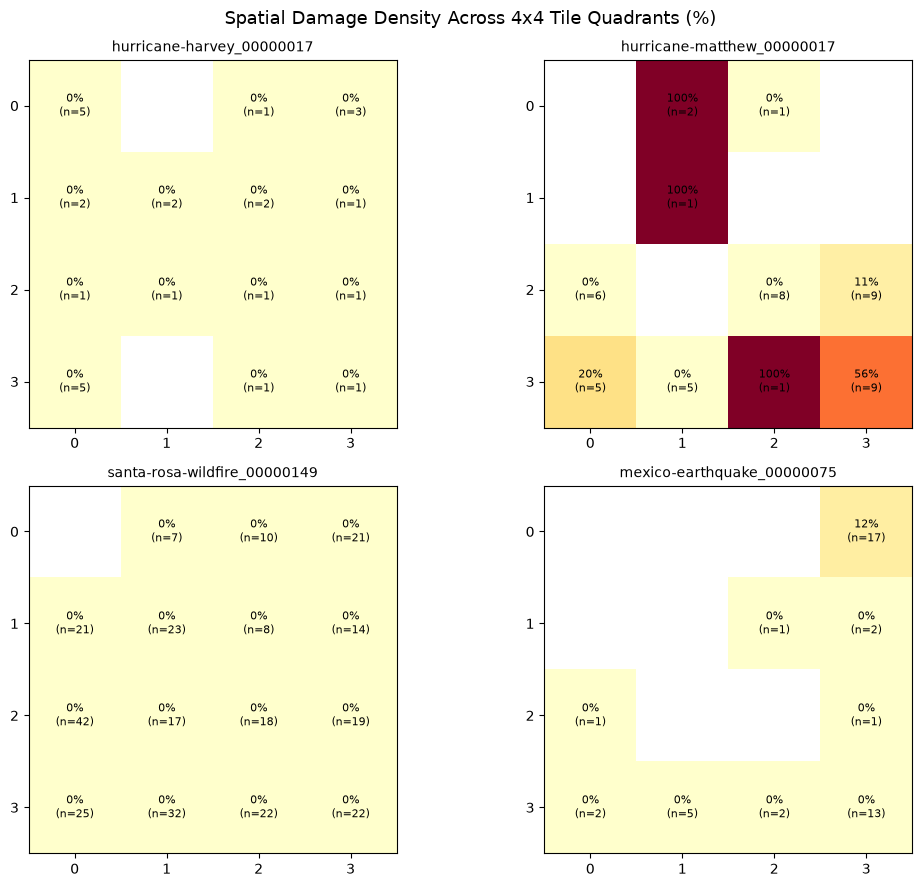

In [6]:
spatial_tiles = [
    "hurricane-harvey_00000017",
    "hurricane-matthew_00000017",
    "santa-rosa-wildfire_00000149",
    "mexico-earthquake_00000075"
]
DAMAGED = {"minor-damage", "major-damage", "destroyed"}
CLASSIFIED = {"no-damage"} | DAMAGED
GRID = 4

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, tile_id in zip(axes.flatten(), spatial_tiles):
    sub = geom_df[geom_df["tile_id"] == tile_id].copy()
    sub = sub[sub["subtype"].isin(CLASSIFIED)]
    heatmap = np.full((GRID, GRID), np.nan)
    counts_grid = np.zeros((GRID, GRID), dtype=int)
    if len(sub) > 0:
        xs = sub["geom"].apply(lambda g: min(int(g.centroid.x / 1024 * GRID), GRID - 1))
        ys = sub["geom"].apply(lambda g: min(int(g.centroid.y / 1024 * GRID), GRID - 1))
        is_dmg = sub["subtype"].isin(DAMAGED)
        for gy in range(GRID):
            for gx in range(GRID):
                mask = (xs == gx) & (ys == gy)
                tot = int(mask.sum())
                counts_grid[gy, gx] = tot
                if tot > 0:
                    heatmap[gy, gx] = is_dmg[mask].sum() / tot * 100
    im = ax.imshow(heatmap, cmap="YlOrRd", vmin=0, vmax=100)
    for gy in range(GRID):
        for gx in range(GRID):
            if counts_grid[gy, gx] > 0:
                ax.text(gx, gy, f"{heatmap[gy, gx]:.0f}%\n(n={counts_grid[gy, gx]})", ha="center", va="center", fontsize=8)
    ax.set_title(tile_id, fontsize=10)
    ax.set_xticks(range(GRID))
    ax.set_yticks(range(GRID))

plt.suptitle("Spatial Damage Density Across 4x4 Tile Quadrants (%)", fontsize=13)
plt.tight_layout()
plt.show()

# 7. Exploratory Data Analysis — Final Conclusions

1. **Visual & Spectral Overlap**: Global RGB pixel intensity shifts minimally between pre- and post-disaster imagery (`< 2` intensity units on average), and raw pixel differences spike due to flooding/illumination rather than structural damage alone. Paired Siamese spatial feature extraction and standardized ImageNet normalization are required.
2. **Severe Imbalance & Event Shift**: 18.4% of tiles contain zero buildings, and 72.1% of annotated buildings are `no-damage`. Severity profiles shift drastically across disasters (e.g., Santa Rosa wildfire 26.8% destroyed vs. Mexico earthquake 99.4% no-damage), requiring guided building sampling and class-balanced/focal objectives.
3. **Geometry Integrity**: Out of 162,787 building annotations, 162,786 parse cleanly; one self-intersecting polygon exists in `hurricane-michael_00000172`, and extreme large polygons (up to `398,012 px^2`) correspond to valid industrial roof complexes and must be retained.